# Digital Twin Integration
by Chris Mimra (UniSQ) 2026

This notebook serves as Software Requirement Document and code-illustration of the scientifically relevant software parts. It is produced by a human who takes full responsibility. The production system is developed in parallel by an AI agent based on this notebook. The software is transferred to a Rapberry Pi system with the cameras and trigger systems attached. 

## General software structure 

The digital twin integration for the monitoring system consists of 8 differnet phases.
1. Preview  (production only, no  notebook) - generates a live-preview of the camera data stream, including camera configuration
2. Calibration (prod only) - capturing of the camera and trigger position
3. Data capturing (prod only) - in-process data gathering 
4. Conversion (prod and nb) - the captured raw data is converted by using Stokes parameter to extract DoLP and AoLP
5. Mapping (prod and nb) - The converted data is mapped to the 3D geometry and the 3D model is flattened.
6. Tow matching (prod and nb) - comparison to the planned tow position from the tow placement file.
7. The average tow orientation of each layer is calculated 
8. The data is exported to the needs of the digital thread in 3DExperinece




In [ ]:
# Imports:

import numpy as np
import matplotlib.pyplot as plt
import os

# User variables (for purposes of this notebook, these are hard-coded):
calib_input_file = r"C:\Users\U8021993\OneDrive - UniSQ\Documents\01_Projects\01_MonitoringSystem_FilamentWindind\02_Software\04_DigitalThreadIntegration\notebooks\calibration_data.npy" #File with emply mandrel for calibration.
cam_img_file = r"C:\Users\U8021993\OneDrive - UniSQ\Documents\01_Projects\01_MonitoringSystem_FilamentWindind\01_Hardware\Camera\Polarising Camera\Pics\2026_07\test_01_2026-07-28T14_31_36\bb_20260728_144450_066.npy" #pol camera data file of mandrel with filament
save_location = r"C:\Users\U8021993\OneDrive - UniSQ\Documents\01_Projects\01_MonitoringSystem_FilamentWindind\02_Software\04_DigitalThreadIntegration\notebooks\bb_20260728_144450_066"

# System settings (hard-coded for notebook, changable in prod UI):
DoLP_threshold = 0.1 # What DoLP value to use as a threshold for masking AoLP values 
polar_pattern = (90, 45, 135, 0) # Polariser angle of each pixel in a 2x2 super-pixel: (top-left, top-right, bottom-left, bottom-right).
view_incidence_threshold = 20

## 1 Preview 

The camera (Basler acA4112-30umPOL - 2048×1500 super-pixels) records images and saves them as .npy files.
The basler pypylon library is used. 

### Requirements
- Production only, as jupyter doesn't support real-time streams.
- Settings (save location, gain, shutter speed) are manually set
- A focus setting option with a preview with highlighted sharp edges
- A GUI with buttons optimised for touch-screen usage. 

## 2 Calibration

This module's purpose is to calibrate the camera system. It consists of two sub systems:
A) Intrinsic calibration of the camera optics: A calibration procedure with a flat calibration board with a checkered pattern is conducted and the intrinsic calibration of the camera is determinded. 
B) Capture the exact position and viewing angle of the camera system, when it is triggered. It works by capturing images of the empty mandrel and comparing reference points to a digital model. From this comparison, the relative position of the camera, it's viewing angle and the rotational position of the trigger on the mandrel.

### Prerequesites
- Set up camera on tripod
- Mechanical triggering system that inititates an image capturing once every revolution of the mandrel. Its a mechanical system with a pin on the rotating axis and is connected to GPIO26 of the RaspPi.
- Flat calibration board with 10x7 tiles on A3 sheet.
- Reference points on empty mandrel and digital model (ARUCO marker + symmetry lines)

### Requirements
- Calibration button on the UI with two tabs: Intrinsic optic and position calibration
- Guided calibration (intrinsic optics) with 12 positions of the board. Automatic extraction of the intrinsic matrices and distortion removal.
- Import of the mandrel's step file. 
- Automated calibration of the camera position in realation to the mandrel through 5 rotations of the mandrel. It saves the positon of the camera in relation to the mandrel's step file origin position. It also saves the rotational position of the trigger pin on the mandrel and  field of view of the camera in relaition to the mandrel.


# 3 Data capturing 

This module captures the raw data from the camera, when the GUI button "record" is activated. It saves the raw data as npy files. There is a GUI slider if the processing of the data should automatically be started or if it is done offline.

## 4 Conversion

### Prerequesites
The previously captured files are loaded and previewed. The DoLP and AoLP images are calculated, previewd and saved.


### Requirements
- The npy files are read and a preview is generated.
- All Stokes parameter and the DoLP and AoLP is calculated.
- A preview of the DoLP and AoLP images is displayed
- The full resolution images of DoLP and AoLP is saved


Input data shape: (3000, 4096)


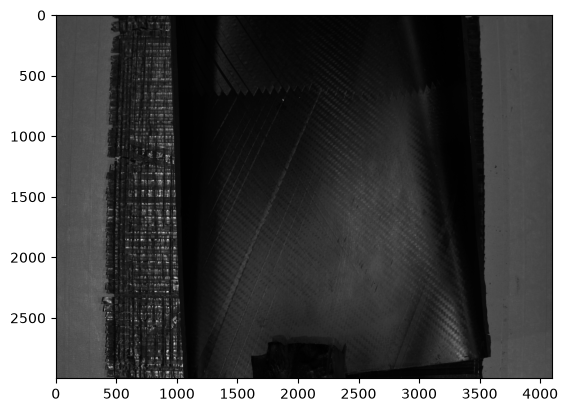

In [ ]:
# import input_file

cam_img_data = np.load(cam_img_file)
print(f"Input data shape: {cam_img_data.shape}")

#Preview the data
plt.imshow(cam_img_data, cmap='gray')


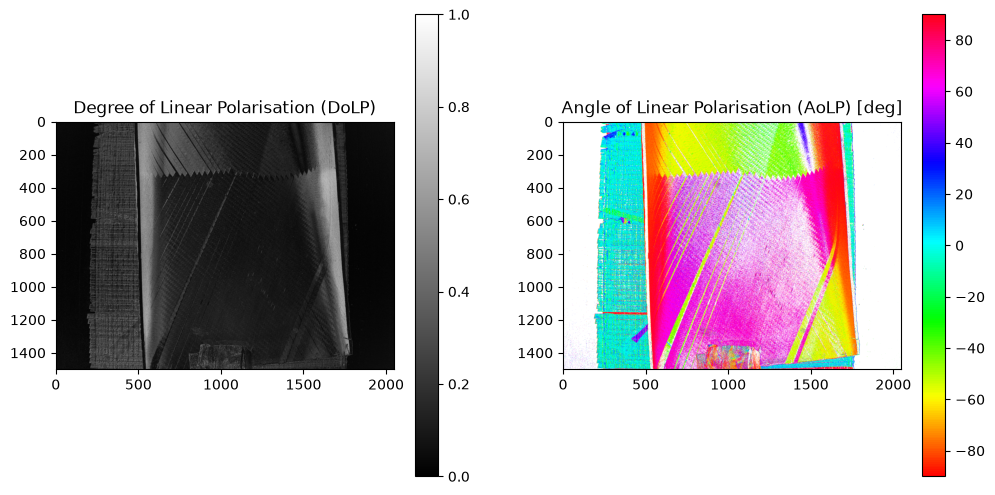

In [ ]:
EPS = 1e-6

# Extract the four polarisation sub-images (half resolution) from the 2x2 super-pixels.
# Cast to float first: the raw data is unsigned integer, so I0 - I90 would otherwise wrap around.
sub_images = {
    polar_pattern[0]: cam_img_data[0::2, 0::2].astype(np.float32),  # top-left
    polar_pattern[1]: cam_img_data[0::2, 1::2].astype(np.float32),  # top-right
    polar_pattern[2]: cam_img_data[1::2, 0::2].astype(np.float32),  # bottom-left
    polar_pattern[3]: cam_img_data[1::2, 1::2].astype(np.float32),  # bottom-right
}
I0, I45, I90, I135 = sub_images[0], sub_images[45], sub_images[90], sub_images[135]

# Stokes parameters
S0 = 0.5 * ((I0 + I90) + (I45 + I135))  # total intensity, averaged over both polariser pairs
S1 = I0 - I90
S2 = I45 - I135

# Polarised / unpolarised intensity
I_pol = np.sqrt(S1**2 + S2**2)
I_unpol = np.clip(S0 - I_pol, 0.0, None)

# Degree of Linear Polarisation [0, 1] and Angle of Linear Polarisation [-pi/2, pi/2]
DoLP = np.clip(I_pol / (S0 + EPS), 0.0, 1.0)
AoLP = 0.5 * np.arctan2(S2, S1)
AoLP_deg = np.degrees(AoLP)  # [-90, 90] deg

# AoLP is only meaningful where the light is sufficiently polarised (suppress noise in low-DoLP areas)
AoLP_deg_masked = AoLP_deg.copy()
AoLP_deg_masked[DoLP < DoLP_threshold] = np.nan

# Preview the DoLP and AoLP images
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(DoLP, cmap='gray', vmin=0, vmax=1)
plt.title('Degree of Linear Polarisation (DoLP)')
plt.colorbar()
plt.subplot(1, 2, 2)
plt.imshow(AoLP_deg_masked, cmap='hsv', vmin=-90, vmax=90)
plt.title('Angle of Linear Polarisation (AoLP) [deg]')
plt.colorbar()
plt.show()

# Save the DoLP and AoLP images as .png files 


os.makedirs(save_location, exist_ok=True)

plt.imsave(f"{save_location}/DoLP.png", DoLP, cmap='gray', vmin=0, vmax=1)
plt.imsave(f"{save_location}/AoLP.png", AoLP_deg_masked, cmap='hsv', vmin=-90, vmax=90)


# 5 Mapping and flattening

The captured data is compensated for optical distortions due to the camera/lense system (based on the intrinsic calibration). The data is then projected on the surface of the mandrel's model and angel differences in due to the viewing incidence are compensated (AoLP to actual fibre angle), resulting in a data set where each pixel is assigned a measured fibre angle, a 3D position, and a 3D surface orientation. This 3D data set is then converted into a flattend gnomonic projection and illustrated. 

## Requirements
- Import of the AoLP, the camera intrinsics, and the camera position. 
- Compensation for optical distortions (adjustment of the pixel position and the AoLP value)
- Mapping of each pixel to the mandrels 3D model (3D position and surface orinetation)
- Adjustment of the AoLP based on the position and surface orientation
- Display and saving option of the gnomonic projection of this dataset.
- Saving of the processed dataset (fibre angle, position, surface angle) as npy


# 6 Tow matching

All images that were captured throughout all revolutions of the FW process of the part, will be analysed. From the tow placement file a gnomonic projection is created for each revolution of the mandrel, indicating the position of the tow placed in this revolution. The "planned" position of that tow's edges are overlayed with the processed image in the gnomonic projection and illustrated. 

## Requirements
- Import a tow placement file (Format: .txt: X, Y, Z, I, J, K, Winding_Angle, Payout_Length, layer number)
- For each revolution, based on the camera position and viewing angle, creation of a gnomonic projection of the last tow
- preview and saving to this comparison image

# 7 Layer orientation

For the last revolution of each layer, the captured and processed image is taken and the average fibre angle is calculated (not in the gnomonic projection but from the npy data).


# 8 Data export 

The data is exported to the needs of the digital thread